In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv("../data/raw/dataset.csv")

In [6]:
print(df.shape)
print(df.head())
df.columns


(1470, 35)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLeve

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [4]:
for col in df.columns:
    print(col)

df.dtypes.value_counts()

df.select_dtypes(include="str").columns

df["Attrition"].value_counts()

df["Attrition"].value_counts(normalize=True) * 100

Age
Attrition
BusinessTravel
DailyRate
Department
DistanceFromHome
Education
EducationField
EmployeeCount
EmployeeNumber
EnvironmentSatisfaction
Gender
HourlyRate
JobInvolvement
JobLevel
JobRole
JobSatisfaction
MaritalStatus
MonthlyIncome
MonthlyRate
NumCompaniesWorked
Over18
OverTime
PercentSalaryHike
PerformanceRating
RelationshipSatisfaction
StandardHours
StockOptionLevel
TotalWorkingYears
TrainingTimesLastYear
WorkLifeBalance
YearsAtCompany
YearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager


Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [7]:
categorical_cols = df.select_dtypes(include="str").columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


Attrition:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

BusinessTravel:
<StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

Department:
<StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str

EducationField:
<StringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str

Gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

JobRole:
<StringArray>
[          'Sales Executive',        'Research Scientist',
     'Laboratory Technician',    'Manufacturing Director',
 'Healthcare Representative',                   'Manager',
      'Sales Representative',         'Research Director',
           'Human Resources']
Length: 9, dtype: str

MaritalStatus:
<StringArray>
['Single', 'Married', 'Divorced']
Length: 3, dtype: str

Over18:
<StringArray>
['Y']
Length: 1, dtype: str

OverTime:
<StringArray>
['Yes', 'No']
L

In [8]:
categorical_cols = df.select_dtypes(include="str").columns



In [9]:
df["Attrition"] = df["Attrition"].map({"No": 0, "Yes": 1})



In [10]:
for col in categorical_cols:
    print(col, "->", df[col].nunique(), "unique value(s)")

Attrition -> 2 unique value(s)
BusinessTravel -> 3 unique value(s)
Department -> 3 unique value(s)
EducationField -> 6 unique value(s)
Gender -> 2 unique value(s)
JobRole -> 9 unique value(s)
MaritalStatus -> 3 unique value(s)
Over18 -> 1 unique value(s)
OverTime -> 2 unique value(s)


In [11]:
df = df.drop(columns=["Over18"])


In [12]:
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [13]:
id_columns_check = ["EmployeeCount", "EmployeeNumber", "StandardHours"]

for col in id_columns_check:
    print(f"\n{col}:")
    print(df[col].nunique(), "unique value(s)")
    print(df[col].unique()[:10])


EmployeeCount:
1 unique value(s)
[1]

EmployeeNumber:
1470 unique value(s)
[ 1  2  4  5  7  8 10 11 12 13]

StandardHours:
1 unique value(s)
[80]


In [14]:
df = df.drop(columns=["EmployeeCount", "EmployeeNumber", "StandardHours"])

df.shape

(1470, 31)

In [15]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Target values:")
print(df["Attrition"].value_counts())

Shape: (1470, 31)
Missing values: 0
Target values:
Attrition
0    1233
1     237
Name: count, dtype: int64


C:\Users\JIYA\AppData\Local\Temp\ipykernel_17396\2125868692.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed", "Left"])


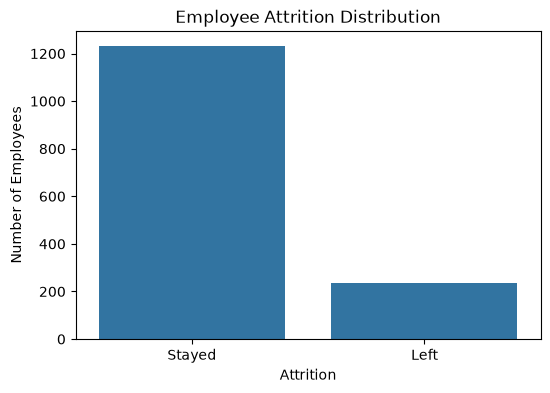

In [16]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(x="Attrition", data=df)

ax.set_xticklabels(["Stayed", "Left"])

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

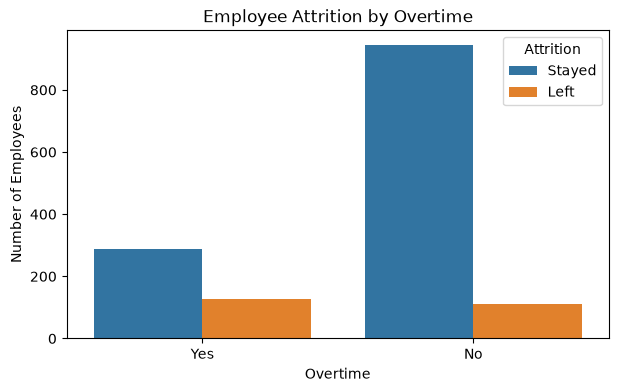

In [18]:
plt.figure(figsize=(7, 4))

sns.countplot(x="OverTime", hue="Attrition", data=df)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.legend(title="Attrition", labels=["Stayed", "Left"])

plt.show()

OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64


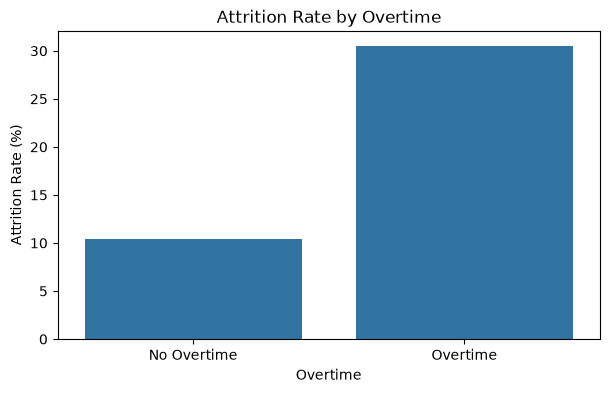

In [20]:
attrition_rate_overtime = df.groupby("OverTime")["Attrition"].mean() * 100

print(attrition_rate_overtime)

plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=["No Overtime", "Overtime"],
    y=attrition_rate_overtime.values
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")

plt.show()

In [21]:
attrition_rate_joblevel = df.groupby("JobLevel")["Attrition"].mean() * 100

print(attrition_rate_joblevel)

JobLevel
1    26.335175
2     9.737828
3    14.678899
4     4.716981
5     7.246377
Name: Attrition, dtype: float64


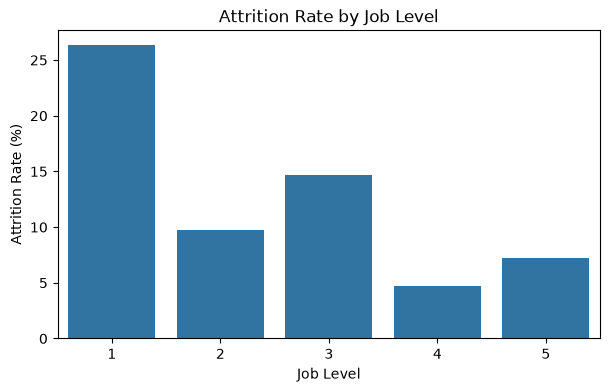

In [22]:
plt.figure(figsize=(7, 4))

sns.barplot(
    x=attrition_rate_joblevel.index,
    y=attrition_rate_joblevel.values
)

plt.title("Attrition Rate by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Attrition Rate (%)")

plt.show()

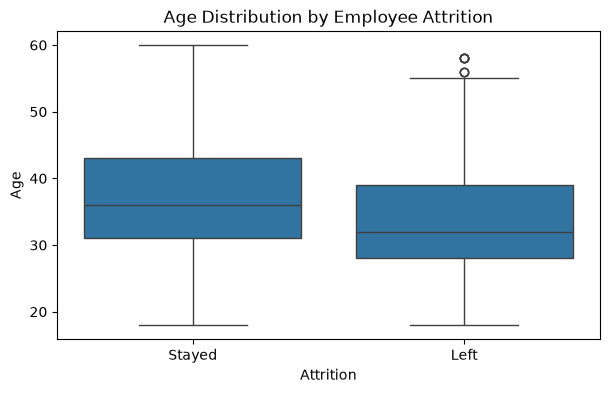

In [23]:
plt.figure(figsize=(7, 4))

sns.boxplot(x="Attrition", y="Age", data=df)

plt.xticks([0, 1], ["Stayed", "Left"])
plt.title("Age Distribution by Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")

plt.show()

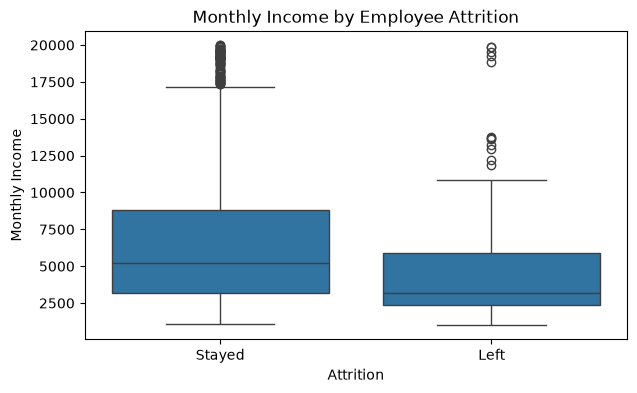

In [24]:
plt.figure(figsize=(7, 4))

sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)

plt.xticks([0, 1], ["Stayed", "Left"])
plt.title("Monthly Income by Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

In [25]:
attrition_rate_satisfaction = df.groupby("JobSatisfaction")["Attrition"].mean() * 100

print(attrition_rate_satisfaction)

JobSatisfaction
1    22.837370
2    16.428571
3    16.515837
4    11.328976
Name: Attrition, dtype: float64


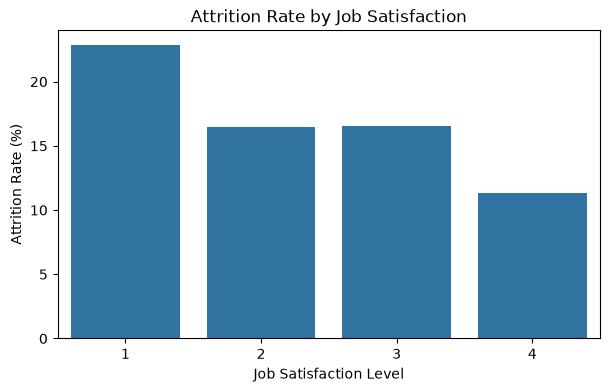

In [26]:
plt.figure(figsize=(7, 4))

sns.barplot(
    x=attrition_rate_satisfaction.index,
    y=attrition_rate_satisfaction.values
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")

plt.show()

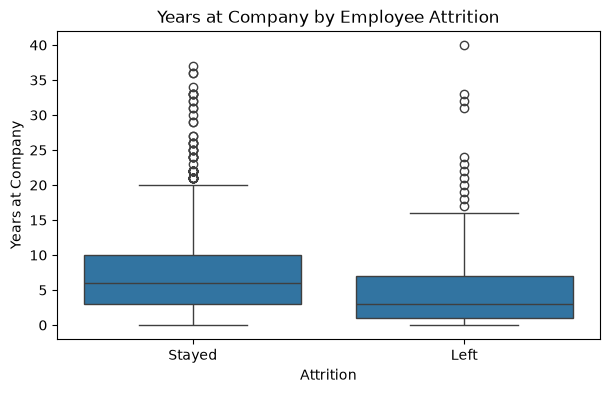

In [27]:
plt.figure(figsize=(7, 4))

sns.boxplot(x="Attrition", y="YearsAtCompany", data=df)

plt.xticks([0, 1], ["Stayed", "Left"])
plt.title("Years at Company by Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

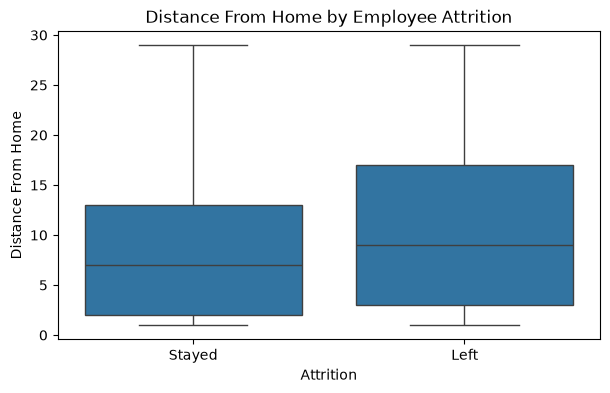

In [28]:
plt.figure(figsize=(7, 4))

sns.boxplot(x="Attrition", y="DistanceFromHome", data=df)

plt.xticks([0, 1], ["Stayed", "Left"])
plt.title("Distance From Home by Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Distance From Home")

plt.show()

In [29]:
jobrole_cols = [col for col in df.columns if col.startswith("JobRole_")]

df["JobRole_Group"] = "Healthcare Representative"

for col in jobrole_cols:
    df.loc[df[col] == 1, "JobRole_Group"] = col.replace("JobRole_", "")

attrition_rate_jobrole = (
    df.groupby("JobRole_Group")["Attrition"].mean() * 100
).sort_values(ascending=False)

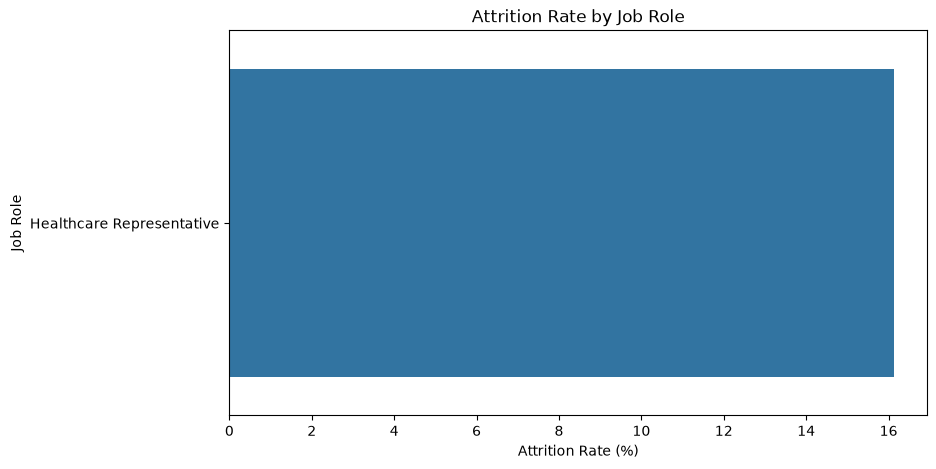

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=attrition_rate_jobrole.values,
    y=attrition_rate_jobrole.index
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.show()

In [31]:
df = df.drop(columns=["JobRole_Group"])

In [ ]:
categorical_features = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "OverTime"
]

df = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)



KeyError: "None of [Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',\n       'MaritalStatus', 'OverTime'],\n      dtype='str')] are in the [columns]"

In [37]:
df.shape

(1470, 45)

In [33]:
df.to_csv("../data/processed/cleaned_encoded.csv", index=False)

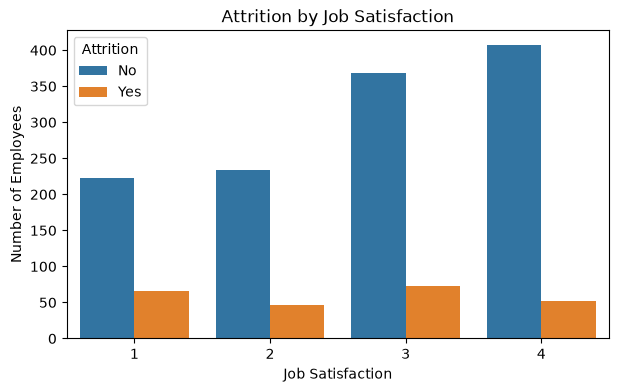

In [9]:
plt.figure(figsize=(7, 4))

sns.countplot(
    x="JobSatisfaction",
    hue="Attrition",
    data=df
)

plt.title("Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")
plt.show()

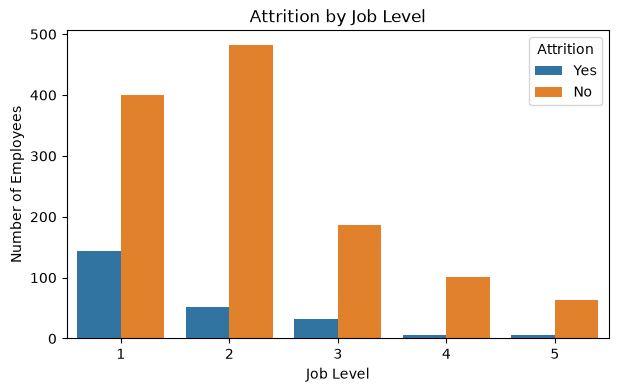

In [10]:
plt.figure(figsize=(7, 4))

sns.countplot(
    x="JobLevel",
    hue="Attrition",
    data=df
)

plt.title("Attrition by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Number of Employees")
plt.show()

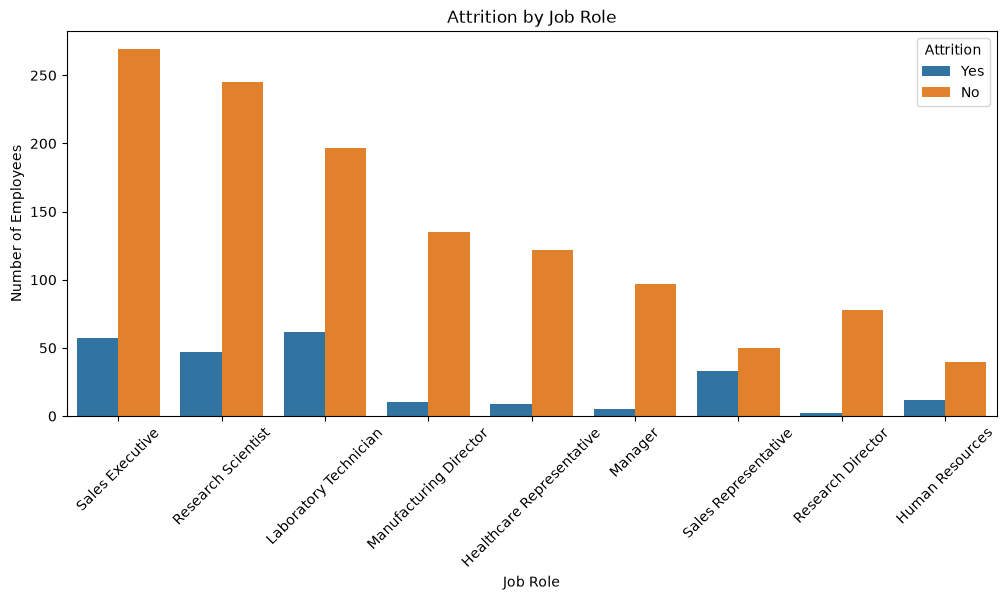

In [11]:
plt.figure(figsize=(12, 5))

sns.countplot(
    x="JobRole",
    hue="Attrition",
    data=df
)

plt.title("Attrition by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.show()

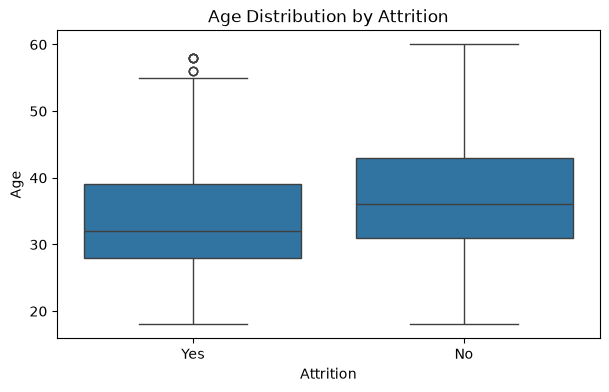

In [12]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    x="Attrition",
    y="Age",
    data=df
)

plt.title("Age Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")
plt.show()

In [13]:
print("Missing values:", df.isnull().sum().sum())

Missing values: 0
